# Final acceptance: five one-width selection

Independently reconstruct the filtering reported in the paper, including individual cuts and target coverage.

**Data:** the frozen 3000-run production set (`data/raw`). **Acceptance:** all five normalized residual magnitudes strictly below one. These are *numerical widths*, not independently measured Gaussian standard deviations.

> Start from the repository root or its `notebooks/` folder. No recomputation of the 3000 DE optimizations is required.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works in Jupyter, VS Code, and Colab if the repository is cloned locally.
workdir = Path.cwd().resolve()
candidates = [workdir, workdir.parent]
ROOT = next((p for p in candidates if (p / "data/raw/runs.csv").is_file()
             and (p / "src/model.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find the repository root. Open the project folder (with data/ and src/) "
        "or clone the repository in the Colab session before running the notebook."
    )
sys.path.insert(0, str(ROOT / "src"))
from model import PARAMETERS, V_EW, MASS_WIDTHS, mass_matrix, spectrum
raw = pd.read_csv(ROOT / "data/raw/runs.csv")
print(f"Repository: {ROOT.name}; records: {len(raw):,}; v = {V_EW} GeV")

Repository: DE_Particle_paper_public; records: 3,000; v = 246.22 GeV


In [2]:
residual_cols = ["z_H1", "z_H2", "z_H3", "z_charged", "z_kappa"]
z_abs = np.abs(raw[residual_cols].to_numpy(float))
mask_mass = (z_abs[:, :3] < 1).all(axis=1)
mask_charged = z_abs[:, 3] < 1
mask_kappa = z_abs[:, 4] < 1
mask_all = (z_abs < 1).all(axis=1)
accepted = raw.loc[mask_all].copy()
representative = (accepted.sort_values(["target_index", "loss", "restart"])
                  .drop_duplicates("target_index").sort_values("target_index"))
assert len(raw) == 3000 and len(accepted) == 2971 and len(representative) == 1000

## Definitions\nFor mass target \(m_i^\star\), \(z_i = |m_i-m_i^\star|/\sigma_i\), with \(\boldsymbol\sigma=(0.05, 0.09, 0.09)\) GeV. For the auxiliaries, \(z_\pm=|M_{H^\pm}-130\,\mathrm{GeV}|/(1\,\mathrm{GeV})\) and \(z_\kappa=|\kappa_{2V}-1.03|/0.05\). The final criterion is the logical conjunction \(z_a<1\) for all five components. The original *optimizer* internal constraints were slightly wider and are not the final post-run selection.

In [3]:
counts = pd.Series({"three masses":int(mask_mass.sum()),"charged scalar":int(mask_charged.sum()),"vector coupling":int(mask_kappa.sum()),"all five":int(mask_all.sum())})
print(counts.to_string())
per_target=accepted.groupby('target_index').size()
print("Accepted restarts per target:\n",per_target.value_counts().sort_index().to_string())
assert counts.to_dict()=={"three masses":2977,"charged scalar":2994,"vector coupling":3000,"all five":2971}
assert per_target.value_counts().sort_index().to_dict()=={2:29,3:971}

three masses       2977
charged scalar     2994
vector coupling    3000
all five           2971
Accepted restarts per target:
 2     29
3    971


## Residual distribution and one-width reference\nThe mass residuals are generally far below the specified widths; the charged-scalar cut is more restrictive for a few restarts.

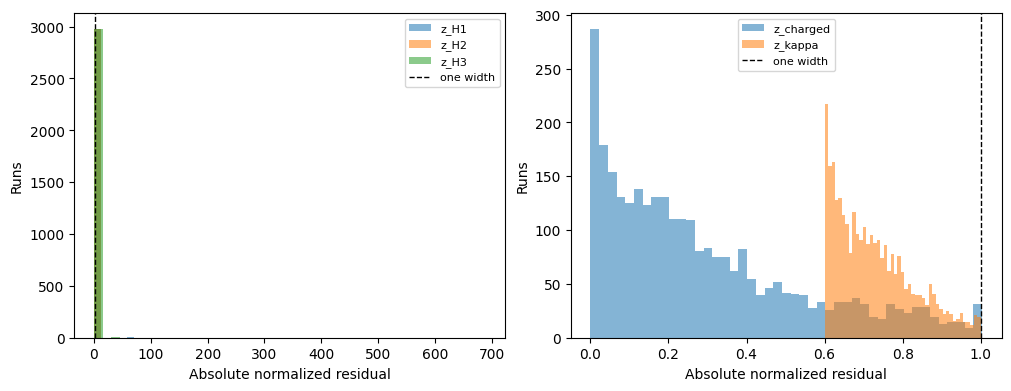

In [4]:
fig, axes = plt.subplots(1,2,figsize=(10,3.8),layout="constrained")
for j,labels in enumerate([["z_H1","z_H2","z_H3"],["z_charged","z_kappa"]]):
    ax=axes[j]
    for lab in labels:ax.hist(np.abs(raw[lab]),bins=45,alpha=.55,label=lab)
    ax.axvline(1,ls="--",c="black",lw=1,label="one width")
    ax.set_xlabel("Absolute normalized residual")
    ax.set_ylabel("Runs")
    ax.legend(fontsize=8)
plt.show()

## Independent forward-model evaluation\nRecompute all five predictions from the *ten stored parameters* rather than trusting precomputed residual columns.

In [5]:
stored=raw[["mass_H1","mass_H2","mass_H3","mc","kappa2V"]].to_numpy(float)
recomputed=np.array([np.r_[spectrum(x)[0], spectrum(x)[3], spectrum(x)[2]]
                     for x in raw[list(PARAMETERS)].to_numpy(float)])
error=np.max(np.abs(stored-recomputed),axis=0)
print(dict(zip(["H1 (GeV)","H2 (GeV)","H3 (GeV)","charged (GeV)","kappa"],error)))
assert np.all(error < 1e-8)

{'H1 (GeV)': np.float64(3.836930773104541e-13), 'H2 (GeV)': np.float64(1.2789769243681803e-13), 'H3 (GeV)': np.float64(1.4210854715202004e-12), 'charged (GeV)': np.float64(1.4210854715202004e-13), 'kappa': np.float64(1.7763568394002505e-15)}
